# Group 27 - EDA Draft (Maria): Member profile and descriptive analysis
 The goal of this notebook is to build a descriptive profile of the ACDC coworking members, using the already cleaned dataset. We want to understand who the members are, which plans they choose, how membership has evolved over the 3 years, and how the main variables relate to each other.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 2. Reading the cleaned data

In [2]:
df_clean = pd.read_csv(
    "../../data/acdc_clean.csv", sep=";",
    parse_dates=["membership_start", "membership_end", "last_badge_swipe"]
)
df = df_clean.copy()
print(df.shape)

(15108, 32)


## 3. Inicial Analysis of the cleaned data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15108 entries, 0 to 15107
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   member_id                    15108 non-null  object        
 1   age                          15108 non-null  float64       
 2   gender                       15108 non-null  object        
 3   industry                     15108 non-null  object        
 4   country                      15108 non-null  object        
 5   is_team_account              15108 non-null  bool          
 6   n_colleagues_on_account      15108 non-null  float64       
 7   plan_tier                    15108 non-null  object        
 8   plan_days_per_week           15108 non-null  int64         
 9   membership_start             15108 non-null  datetime64[ns]
 10  membership_end               11206 non-null  datetime64[ns]
 11  last_badge_swipe             15108 non-nu

From the 31 columns, only membership_end has some null values, which makes sense since the data was already cleaned and probably those are costumers whose membership is still valid.


In [4]:
metric_features = df.select_dtypes(include="number").columns.tolist()
non_metric_features = [c for c in df.select_dtypes(exclude="number").columns
                       if c != "member_id"]
print(metric_features)
print(non_metric_features)

['age', 'n_colleagues_on_account', 'plan_days_per_week', 'days_since_last_visit', 'total_visits', 'avg_weekly_visits', 'entitled_visits_last_period', 'actual_visits_last_period', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'n_renewals', 'lifetime_value']
['gender', 'industry', 'country', 'is_team_account', 'plan_tier', 'membership_start', 'membership_end', 'last_badge_swipe', 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes', 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'ltv_imputed']


In [5]:
#para os gráficos ficarem sempre pela mesma ordem do mais barato ao mais caro
p_order = ["hot_desk", "flex", "full_time", "dedicated_desk", "private_office"]
print(df["plan_tier"].unique())


['hot_desk' 'flex' 'dedicated_desk' 'full_time' 'private_office']


In order to have always the same order, from least expensive to the most expensive.

## 4. Customer Demographics

### 4.1. Age

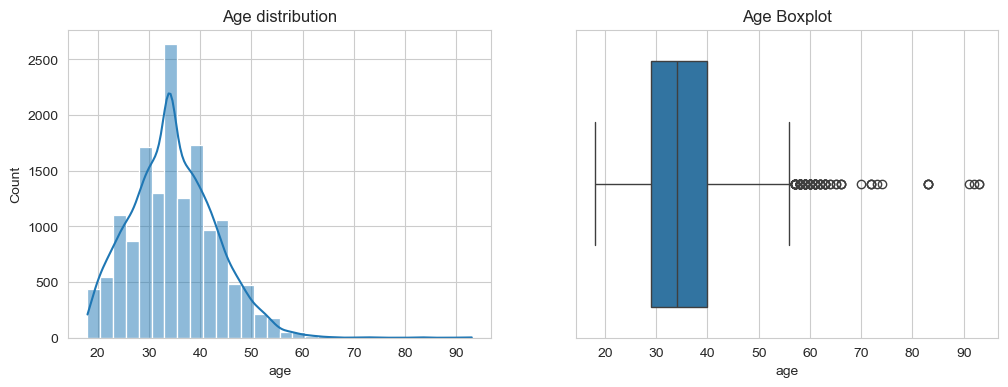

count    15108.000000
mean        34.723061
std          8.211885
min         18.000000
25%         29.000000
50%         34.000000
75%         40.000000
max         93.000000
Name: age, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age distribution")
sns.boxplot(x=df["age"], ax=axes[1])
axes[1].set_title("Age Boxplot")
plt.show()

print(df["age"].describe())

The mean and median are almost the same, the distribution is symmetric without bias. 

The interquartile range goes from 29 to 40 years which means half of the custumeres have this age, being 34 the most common age.

75% of the members have until 40 years. The age 93 is the furthest outlier which doesen't seem very plausible in this context.

### 4.2. Gender, Industry, Country

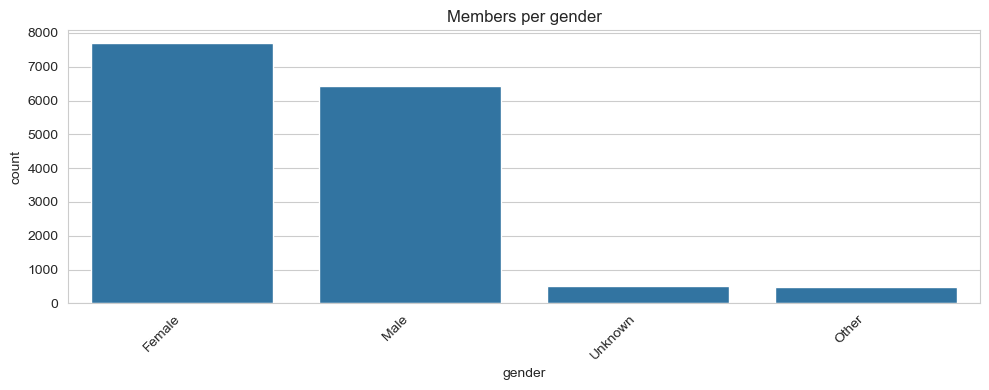

gender
Female     0.509
Male       0.425
Unknown    0.034
Other      0.032
Name: proportion, dtype: float64


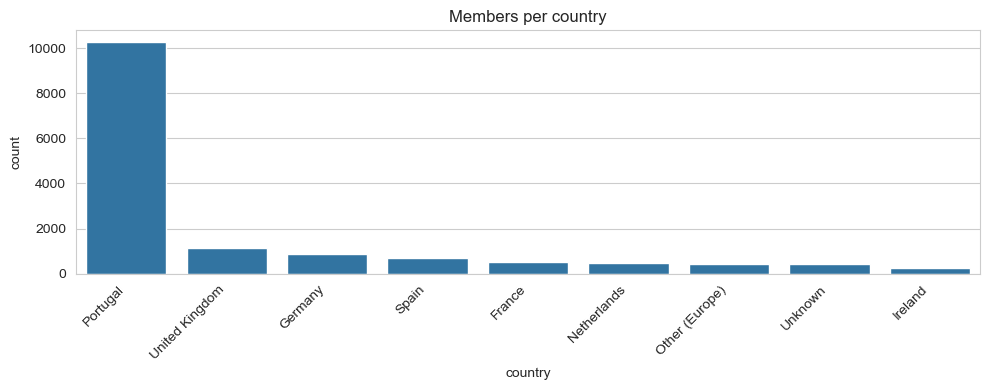

country
Portugal          0.680
United Kingdom    0.076
Germany           0.058
Spain             0.047
France            0.035
Netherlands       0.032
Other (Europe)    0.029
Unknown           0.027
Ireland           0.016
Name: proportion, dtype: float64


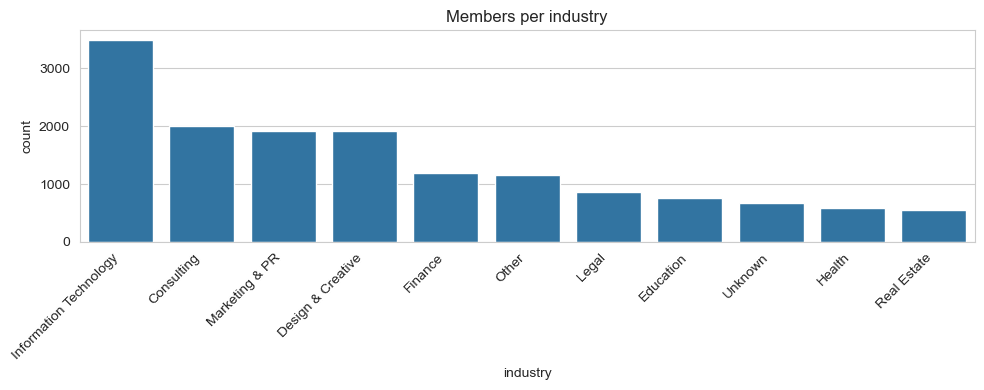

industry
Information Technology    0.231
Consulting                0.133
Marketing & PR            0.127
Design & Creative         0.127
Finance                   0.079
Other                     0.077
Legal                     0.057
Education                 0.050
Unknown                   0.044
Health                    0.038
Real Estate               0.036
Name: proportion, dtype: float64


In [7]:
for col in ["gender", "country", "industry"]:
    plt.figure(figsize=(10, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.xticks(rotation=45, ha="right")
    plt.title(f"Members per {col}")
    plt.tight_layout()
    plt.show()
    print(df[col].value_counts(normalize=True).round(3))

There's a small feminine majority.

Portugal is clearly the most common country which makes sense.

The biggest industry is Information Technology with almost twice as the next, Consulting.

### 4.3 Lifetime Value, Visits and Age by Plan Tier

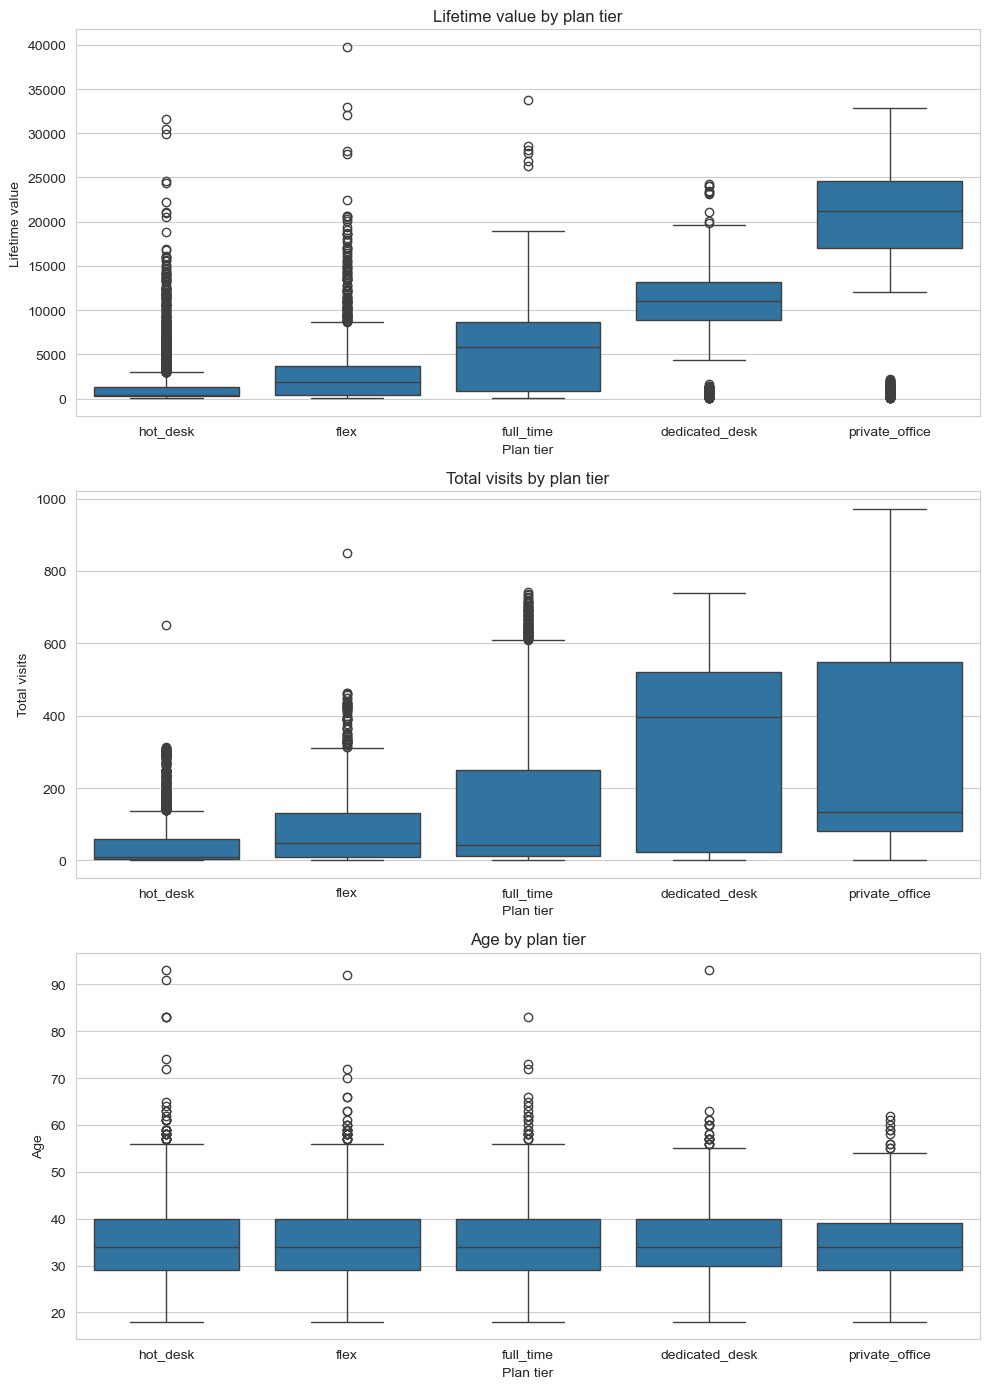

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 14))

for ax, col, label in zip(axes,
                          ["lifetime_value", "total_visits", "age"],
                          ["Lifetime value", "Total visits", "Age"]):
    sns.boxplot(data=df, x="plan_tier", y=col, order=p_order, ax=ax)
    ax.set_title(f"{label} by plan tier")
    ax.set_xlabel("Plan tier")
    ax.set_ylabel(label)

plt.tight_layout()
plt.show()

In [25]:
print(df.groupby("plan_tier")[["lifetime_value", "total_visits", "age"]]
        .median().loc[p_order].round(1))

                lifetime_value  total_visits   age
plan_tier                                         
hot_desk                 357.2          10.0  34.0
flex                    1847.8          47.0  34.0
full_time               5868.5          42.0  34.0
dedicated_desk         11045.8         396.0  34.0
private_office         21161.2         133.0  34.0


- Lifetime value rises with plan tier, from about 360 in hot desk to 21 200 in private office.
- As for visits the median peaks at dedicated desk (396) and drops to 133 in private office.
- The age is identical trough all plans, with a median of 34.

### 4.4. Plan and Account

C:\Users\maria\AppData\Local\Temp\ipykernel_16488\2501808181.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(["Individual", "Team"])


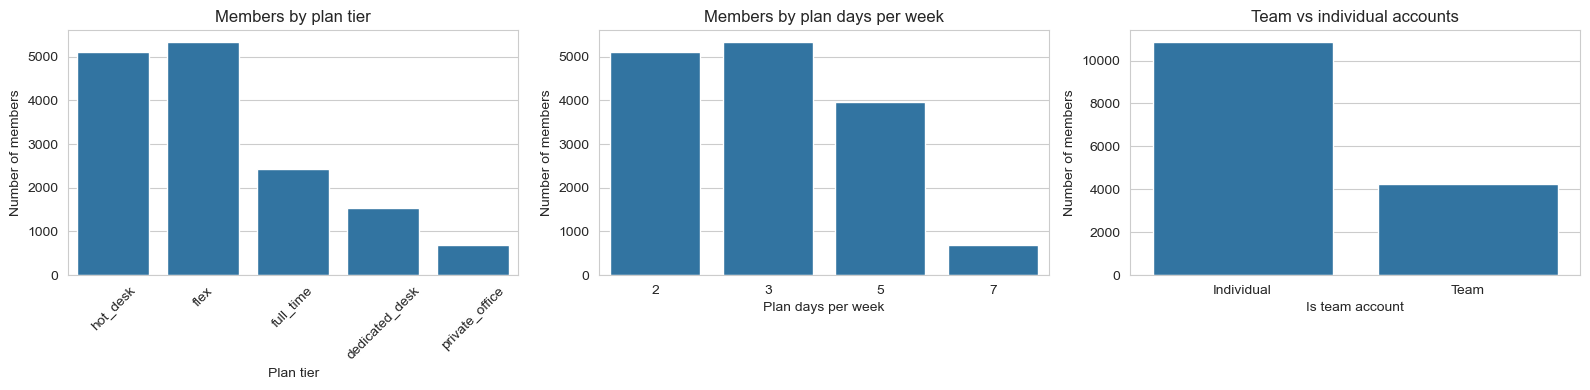

In [8]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(data=df, x="plan_tier", order=p_order, ax=axes[0])
axes[0].set_title("Members by plan tier")
axes[0].set_xlabel("Plan tier")
axes[0].set_ylabel("Number of members")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(data=df, x="plan_days_per_week", ax=axes[1])
axes[1].set_title("Members by plan days per week")
axes[1].set_xlabel("Plan days per week")
axes[1].set_ylabel("Number of members")

sns.countplot(data=df, x="is_team_account", ax=axes[2])
axes[2].set_title("Team vs individual accounts")
axes[2].set_xlabel("Is team account")
axes[2].set_ylabel("Number of members")
axes[2].set_xticklabels(["Individual", "Team"])

plt.tight_layout()
plt.show()

The most frequent plans are hot_desk and flex, and the rarest is private_office, as expected.
Sames for the plan days per weak, less days are more frequent.

Most of the customers have an indivudual acoount.


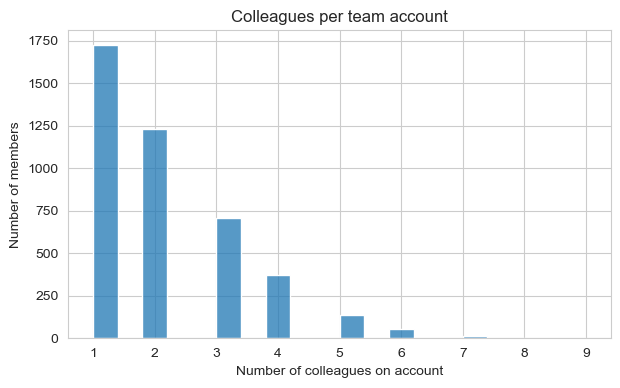

count    4248.000000
mean        2.104755
std         1.232782
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         9.000000
Name: n_colleagues_on_account, dtype: float64


In [9]:
team = df[df["is_team_account"]]

plt.figure(figsize=(7, 4))
sns.histplot(team["n_colleagues_on_account"], bins=20)
plt.title("Colleagues per team account")
plt.xlabel("Number of colleagues on account")
plt.ylabel("Number of members")
plt.show()

print(team["n_colleagues_on_account"].describe())

There's 4241 members in colleagues accounts, about 28% of the customers.
Most of them have 1 colleague per team account (which means a team account of 2).

## 5. Time trends

### 5.1. New members per month

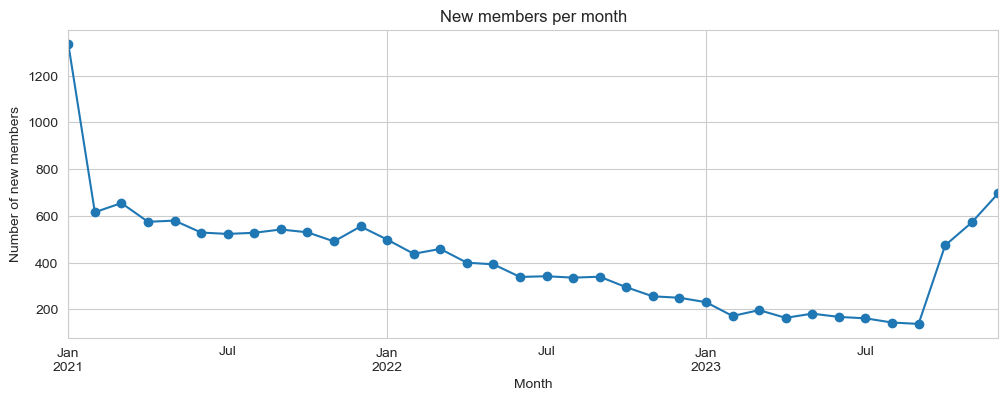

In [10]:
new_per_month = df.groupby(df["membership_start"].dt.to_period("M")).size()

new_per_month.plot(figsize=(12, 4), marker="o")
plt.title("New members per month")
plt.xlabel("Month")
plt.ylabel("Number of new members")
plt.show()

It is very visible that the time where there was most new members per month is January 2021. It may be the start of the observation window. Members who already existed before were recorded with a start date in that month. If so, they are not real new clients.

There's a gradual fall from Jan 2021 to somewhere near July 2023. It starts at 600 and ends up at less then 200 new members.

Finnaly, there's a rise in the last 3 months of 2023, reaching almost 700 new customers in december. It can be related to a sucessfull campain.

### 5.2. Active members per month

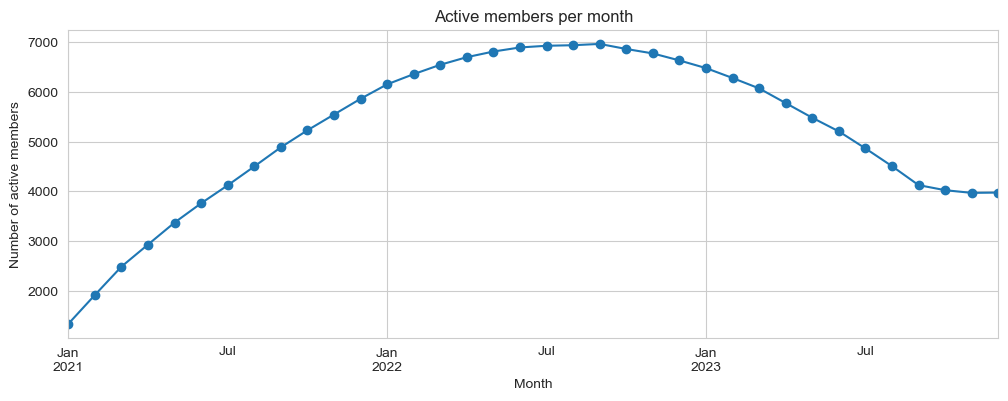

2023-12    3976
Freq: M, dtype: int64


In [31]:
months = pd.period_range(df["membership_start"].min().to_period("M"),
                         pd.Timestamp("2023-12-01").to_period("M"), freq="M")

joined = df.groupby(df["membership_start"].dt.to_period("M")).size().reindex(months, fill_value=0)
left_m = (df.dropna(subset=["membership_end"])
            .groupby(df["membership_end"].dt.to_period("M")).size()
            .reindex(months, fill_value=0))

active_per_month = (joined - left_m).cumsum()

active_per_month.plot(figsize=(12, 4), marker="o")
plt.title("Active members per month")
plt.xlabel("Month")
plt.ylabel("Number of active members")
plt.show()

print(active_per_month.tail(1))

Active members grow grow steadily from January 2021 to a peak (7000) in July 2022, then declines through 2023. 

By the end we have 3976 active members.

### 5.3. Members leaving per month

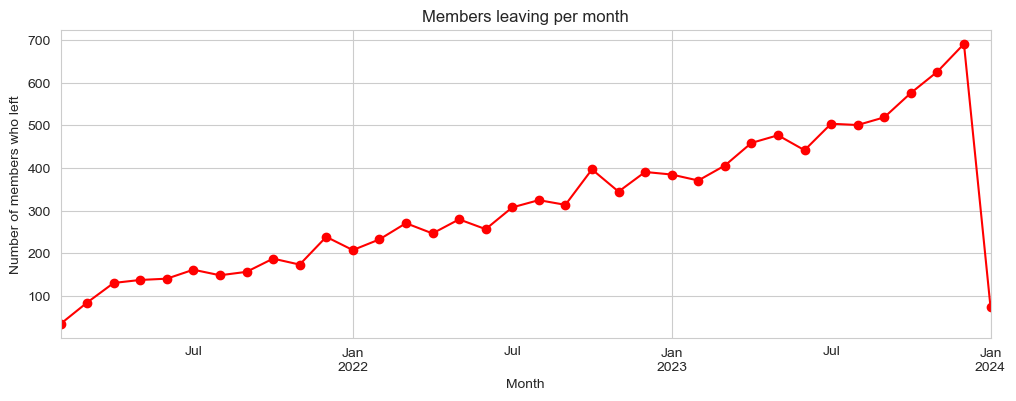

In [11]:
left = df.dropna(subset=["membership_end"])
left_per_month = left.groupby(left["membership_end"].dt.to_period("M")).size()

left_per_month.plot(figsize=(12, 4), marker="o", color="red")
plt.title("Members leaving per month")
plt.xlabel("Month")
plt.ylabel("Number of members who left")
plt.show()

The number of members leaving per month seems to be increasing gradualy through out the months.

Only members who already left appear in this chart, so near the extraction date, Jan 2024, the counts drop, recent joiners had little time to leave and departures after that date are not in the data.

### 5.4. Days with membership

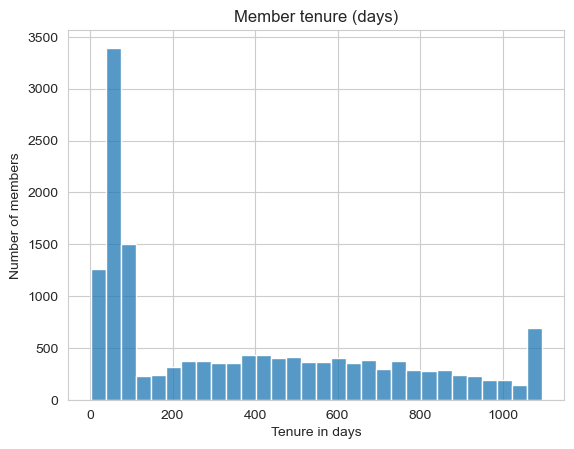

count    15108.000000
mean       374.094586
std        338.607673
min          2.000000
25%         65.000000
50%        282.000000
75%        635.000000
max       1095.000000
Name: tenure_days, dtype: float64


In [12]:
extraction_date = pd.Timestamp("2024-01-01")
end = df["membership_end"].fillna(extraction_date)
df["tenure_days"] = (end - df["membership_start"]).dt.days

sns.histplot(df["tenure_days"], bins=30)
plt.title("Member tenure (days)")
plt.xlabel("Tenure in days")
plt.ylabel("Number of members")
plt.show()

print(df["tenure_days"].describe())

The mean of member tenure is 374 days and theirs a lot od deviation between the values.

75% of the members stayed until 635 days, only 25% stayed 635 or more days.

### 5.5. Member cohorts

In [26]:
df["cohort"] = df["membership_start"].dt.to_period("Q").astype(str)

cohort_summary = df.groupby("cohort").agg(
    members=("member_id", "count"),
    churn_rate=("membership_end", lambda s: s.notna().mean()),
    median_tenure_days=("tenure_days", "median"),
    mean_ltv=("lifetime_value", "mean"),
).round(2)
print(cohort_summary)

        members  churn_rate  median_tenure_days  mean_ltv
cohort                                                   
2021Q1     2607        0.73               825.0   9436.34
2021Q2     1684        0.87               527.5   5918.45
2021Q3     1593        0.83               511.0   5284.87
2021Q4     1576        0.79               469.0   4410.40
2022Q1     1396        0.81               399.0   3679.07
2022Q2     1132        0.81               327.0   2941.09
2022Q3     1018        0.84               227.0   2052.17
2022Q4      801        0.87               101.0   1501.76
2023Q1      600        0.97                79.0    862.02
2023Q2      514        0.96                71.0    574.76
2023Q3      444        0.96                64.0    392.97
2023Q4     1743        0.10                38.0    342.73


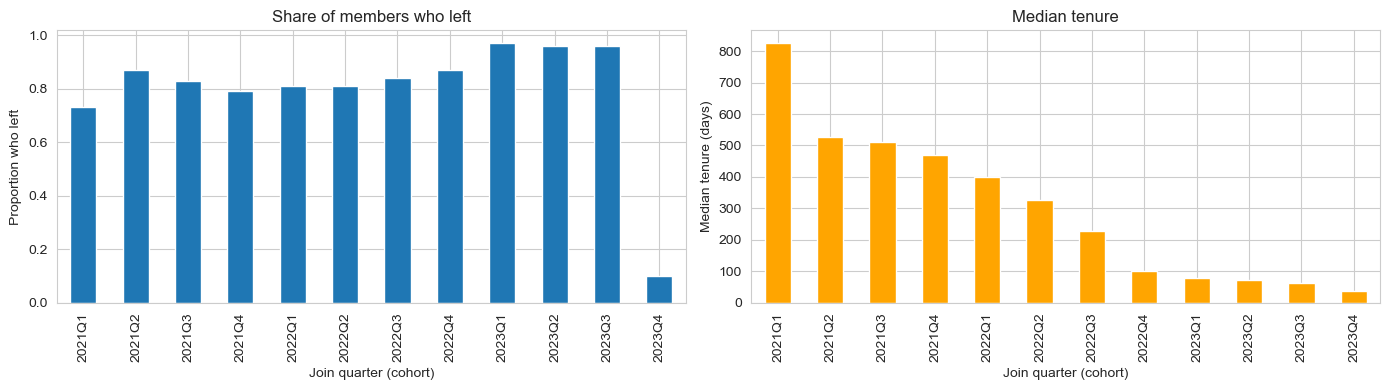

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

cohort_summary["churn_rate"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Share of members who left")
axes[0].set_xlabel("Join quarter (cohort)")
axes[0].set_ylabel("Proportion who left")

cohort_summary["median_tenure_days"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Median tenure")
axes[1].set_xlabel("Join quarter (cohort)")
axes[1].set_ylabel("Median tenure (days)")

plt.tight_layout()
plt.show()

Older cohorts stay a lot longer, median tenure drops significantly. The same for average lifetime values.

The share of members who left is high in every cohort, except 2023Q3 most certainly because most members are still active.

We must keep in mind that recent cohorts have had less time to stay, accumulate value or leave.

## 6. Numeric relashionships

In [13]:
#agora existe a variável tenure_days então atualizamos a lista
metric_features = df.select_dtypes(include="number").columns.tolist()

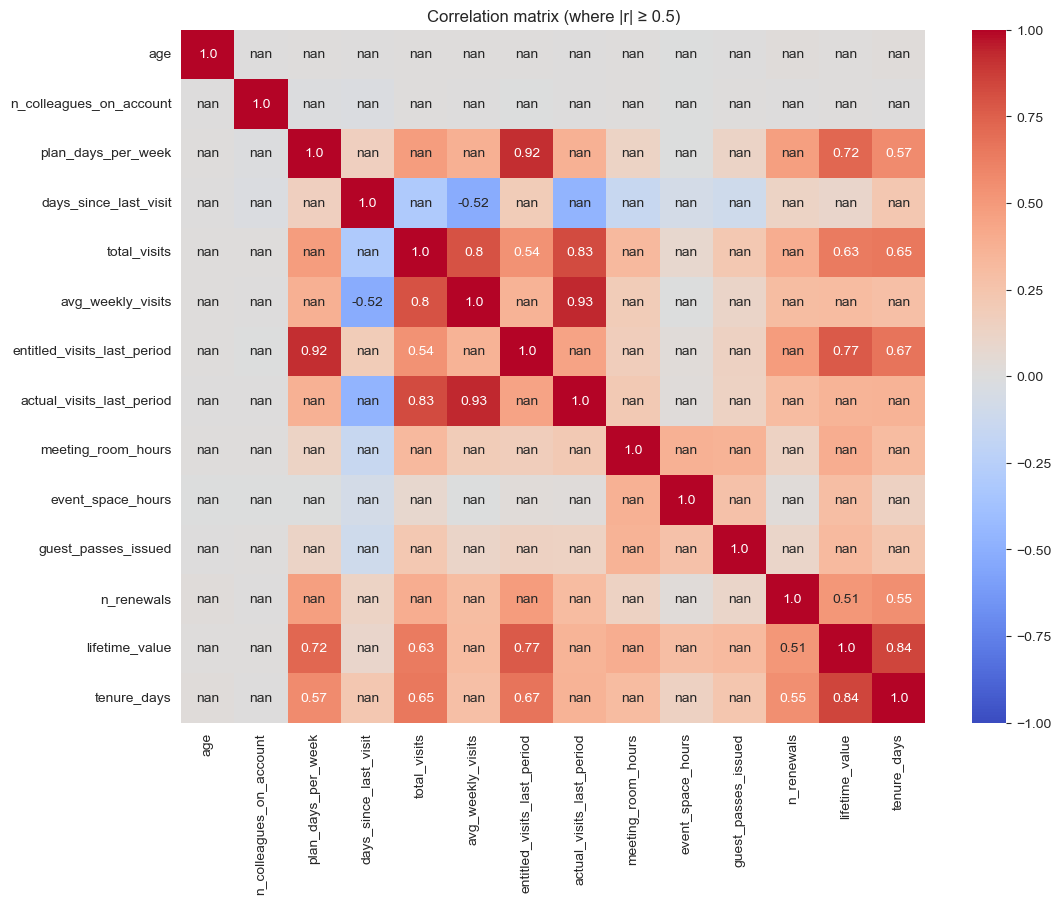

In [14]:
corr = df[metric_features].corr()
strong = corr.abs() >= 0.5

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=corr.where(strong).round(2), fmt="",
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (where |r| ≥ 0.5)")
plt.show()

Only correlations with |r| >= 0.5 are considered, to keep the heatmap readable.

Actual visits last period and plan days per week and total visits are strongly correlated with each other (0.93 and 0.83), and lifetime value is strongly correlated to tenure (r = 0.85), while age, team size, meeting room, event space and guest pass usage show no strong linear relationships.

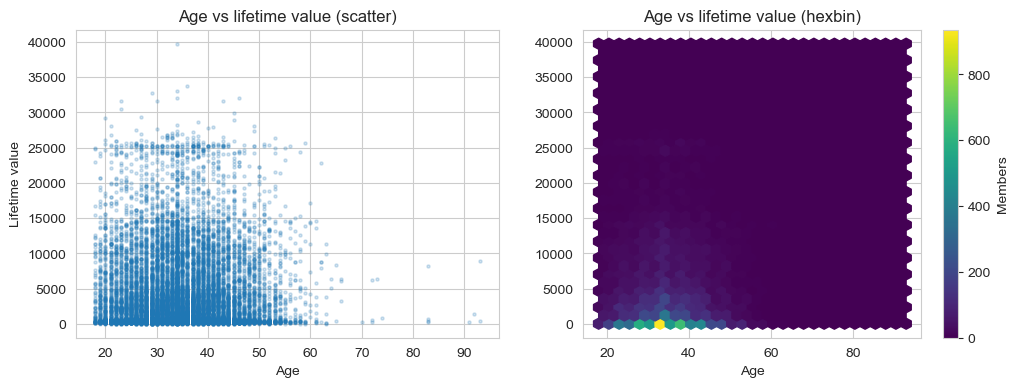

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df["age"], df["lifetime_value"], alpha=0.2, s=5)
axes[0].set_title("Age vs lifetime value (scatter)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Lifetime value")

hb = axes[1].hexbin(df["age"], df["lifetime_value"], gridsize=30, cmap="viridis")
axes[1].set_title("Age vs lifetime value (hexbin)")
axes[1].set_xlabel("Age")
fig.colorbar(hb, ax=axes[1], label="Members")
plt.show()

The age and the lifetime value don't seem to be correlated. Members from all ages have very different values. We can see the most concentration between ages 25 and 45 with a low lifetime value associated. There's very few values above 60.

This makes sense, on the heatmap we concluded that age ddin't have much correlation with the other variables.

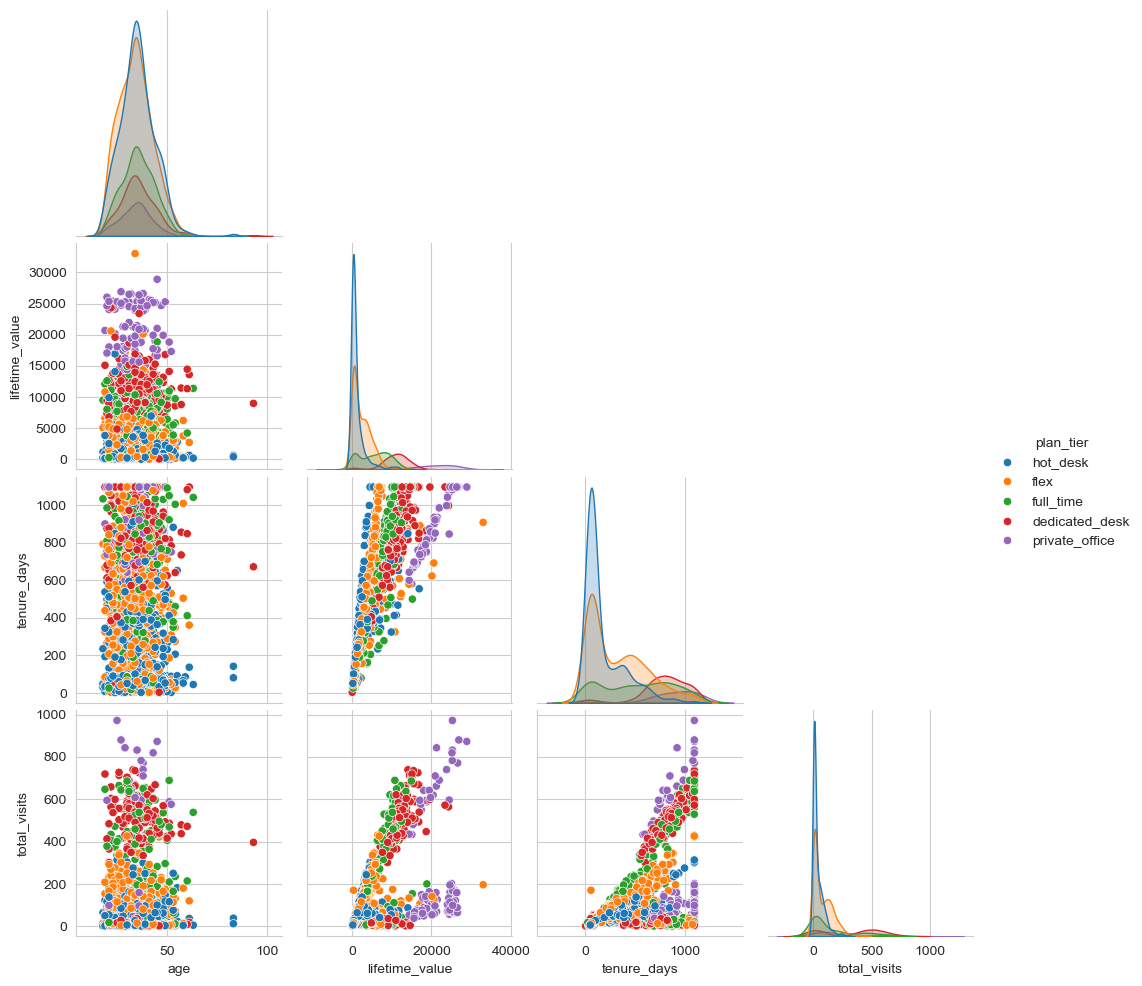

In [16]:
cols = ["age", "lifetime_value", "tenure_days", "total_visits", "plan_tier"]
sns.pairplot(df[cols].sample(2000, random_state=1),
             hue="plan_tier", hue_order=p_order, corner=True)
plt.show()

This pair plot shows that the plan tier separetes members mainly by lifetime value and tenure days.

As expected, the hot desk and flex concentrate more on low values, meanwhile dedicated desk and private office reach the highest values.



## 7. Plan profiles

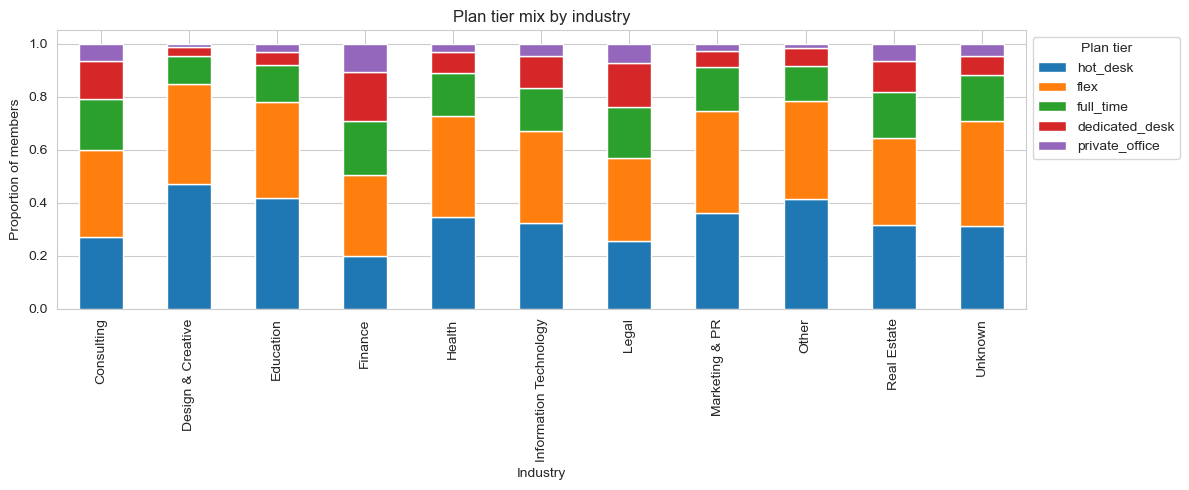

In [17]:
ct = pd.crosstab(df["industry"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by industry")
plt.xlabel("Industry")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Design & Creative and education have less expensive plans (hot desk about 45%).

On the other hand, Finance and Legal have higher tier plans (Finance has about 30% private office + dedicated desk).

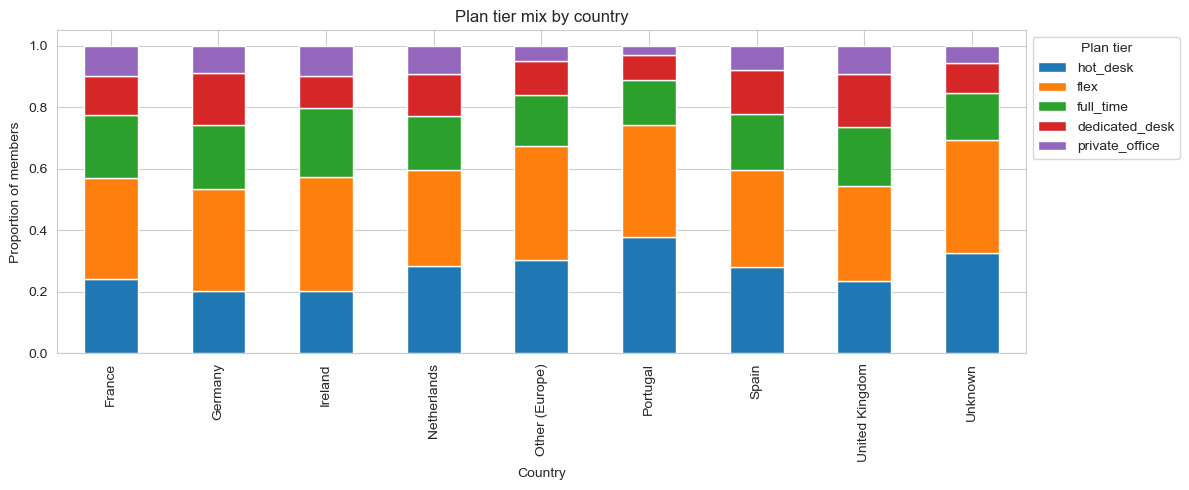

In [18]:
ct = pd.crosstab(df["country"], df["plan_tier"], normalize="index")[p_order]
ct.plot(kind="bar", stacked=True, figsize=(12, 5))
plt.title("Plan tier mix by country")
plt.xlabel("Country")
plt.ylabel("Proportion of members")
plt.legend(title="Plan tier", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Portugal has the highest percentage of low cost plans, while United Kingdom, Germany and France have more members with the plns dedicated desk and private office.

## 8. Redundant variables

In [19]:
corr_abs = df[metric_features].corr().abs()
pairs = (corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
         .stack().sort_values(ascending=False))
print(pairs[pairs > 0.8])

avg_weekly_visits   actual_visits_last_period      0.932189
plan_days_per_week  entitled_visits_last_period    0.917123
lifetime_value      tenure_days                    0.844128
total_visits        actual_visits_last_period      0.826656
                    avg_weekly_visits              0.800994
dtype: float64


This are the five pairs of variables with correlation above 0.8. 

It forms three groups of redundancy: 

- visit frequency: avg_weekly_visits, actual_visits_last_period, total_visits
- contracted days: plan_days_per_week, entitled_visits_last_period
- value: lifetime_value, tenure_days

We should keep one variable per group, and drop the others.

#### Implications for clustering

Our descriptive analysis shows that the ACDC member base is quite homogeneous in demographics (median age of 34 in every plan, mostly Portuguese, with Information Technology as the largest industry), so age, gender and country are unlikely to separate natural groups.

On the other hand, behaviour and value differ. Lifetime value rises with plan tier, while visits don´t (private office members pay the most but have a median of only 133 visits, against 396 for dedicated desk).

Tenure and cohorts also point to distinct profiles, we could see short stays with long term members.

A lot of variables are redundant, we have to make that decision before clustering.

Together, these findings suggest that clusters will be driven by usage, plan value and tenure rather than by demographics.

We should also be careful about handling about observation-window effects so they are not mistaken for real segments.